In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving weatherAUS.csv to weatherAUS.csv


In [ ]:
df = pd.read_csv("weatherAUS.csv")

print(df.head())
print(df.shape)
print(df.info())

         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  Temp3pm  RainToday  \
0       1007.7    

In [ ]:
X = df.drop("RainTomorrow", axis=1)
y = df["RainTomorrow"]

In [ ]:
X = X.drop("Date", axis=1)

In [ ]:
# Handle missing values
for column in X.columns:
    if X[column].dtype == "object":
        X[column] = X[column].fillna(X[column].mode()[0])
    else:
        X[column] = X[column].fillna(X[column].median())

y = y.fillna(y.mode()[0])

In [ ]:
encoder = LabelEncoder()

for column in X.select_dtypes(include="object").columns:
    X[column] = encoder.fit_transform(X[column])

y = encoder.fit_transform(y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (116368, 21)
Testing data: (29092, 21)


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
model = SVC(kernel="rbf")

model.fit(X_train, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [ ]:
y_pred = model.predict(X_test)

print("Prediction completed.")
print(y_pred[:20])

Prediction completed.
[1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy)

SVM Accuracy: 0.851024336587378


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[21808   864]
 [ 3470  2950]]


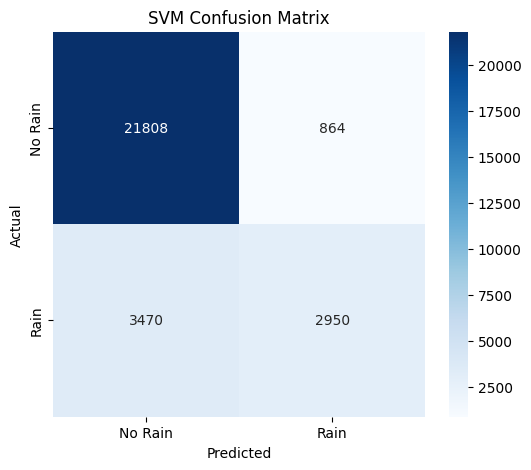

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91     22672
           1       0.77      0.46      0.58      6420

    accuracy                           0.85     29092
   macro avg       0.82      0.71      0.74     29092
weighted avg       0.84      0.85      0.84     29092

